# Project 4 starter: shared Setup cells and section skeleton

This notebook is the shared starting point for both tracks (team contract, Section 3). Each of us copies it to our own notebook, trackA.ipynb or trackB.ipynb, and writes only under our own track's headings. On Sun Nov 22 we merge by pasting each track's cells into these same headings, so the final notebook keeps this order.

The Setup section is shared. Neither of us changes it without the other agreeing.

Code follows the official documentation examples of the tools we use. Every code cell starts with a comment that says either Source, naming the documentation page and example the code follows, or Custom, saying why no example fits.

Lines marked DEFAULT are the contract's defaults, kept until the TA confirms or changes them.


## Setup (shared)

In [1]:
# Custom: shared settings both tracks use (contract Section 3); each track imports its own algorithms in its own cells
import os

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
from sklearn.datasets import make_circles, make_moons
from sklearn.preprocessing import FunctionTransformer, StandardScaler

RANDOM_STATE = 21

# results/ is gitignored (local outputs), figures/ holds report figures, handoff/ holds the files the tracks swap on Nov 19
for folder in ["results", "figures", "handoff"]:
    os.makedirs(folder, exist_ok=True)

print("numpy", np.__version__, "| pandas", pd.__version__, "| scipy", scipy.__version__,
      "| sklearn", sklearn.__version__, "| matplotlib", matplotlib.__version__)

numpy 2.5.3 | pandas 3.0.6 | scipy 1.18.1 | sklearn 1.9.1 | matplotlib 3.11.2


### Task 4.1: Preprocessing & Standardization

Spec: "Implement scale normalization using StandardScaler to eliminate feature swamping. Handle skewed features via log-transformation prior to Euclidean distance calculations."

#### Wholesale Customers (Track A)

In [2]:
# loading wholesale data, 440 clients
wholesale = pd.read_csv("data/Wholesale customers data.csv")
print(wholesale.shape)
wholesale.head()

(440, 8)


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


In [3]:
# DEFAULT (confirm with TA): Channel and Region are category codes, so they stay out of the distance features
SPEND_COLS = ["Fresh", "Milk", "Grocery", "Frozen", "Detergents_Paper", "Delicassen"]

# Source: sklearn FunctionTransformer docs, Examples section: FunctionTransformer(np.log1p)
log_spend = FunctionTransformer(np.log1p).fit_transform(wholesale[SPEND_COLS])

# Source: sklearn StandardScaler docs, fit_transform
X_wholesale = StandardScaler().fit_transform(log_spend)

print("X_wholesale:", X_wholesale.shape)
print("column means:", X_wholesale.mean(axis=0).round(3))
print("column stds: ", X_wholesale.std(axis=0).round(3))

X_wholesale: (440, 6)
column means: [ 0. -0. -0.  0. -0. -0.]
column stds:  [1. 1. 1. 1. 1. 1.]


In [4]:
# Custom: skewness before and after the log, the Task 4.1 evidence for the report (pandas DataFrame.skew)
skew_table = pd.DataFrame({"raw": wholesale[SPEND_COLS].skew(),
                           "after log1p": log_spend.skew()})
skew_table.round(2)

,raw,after log1p
Fresh,2.56,-1.58
Milk,4.05,-0.22
Grocery,3.59,-0.67
Frozen,5.91,-0.35
Detergents_Paper,3.63,-0.24
Delicassen,11.15,-1.09


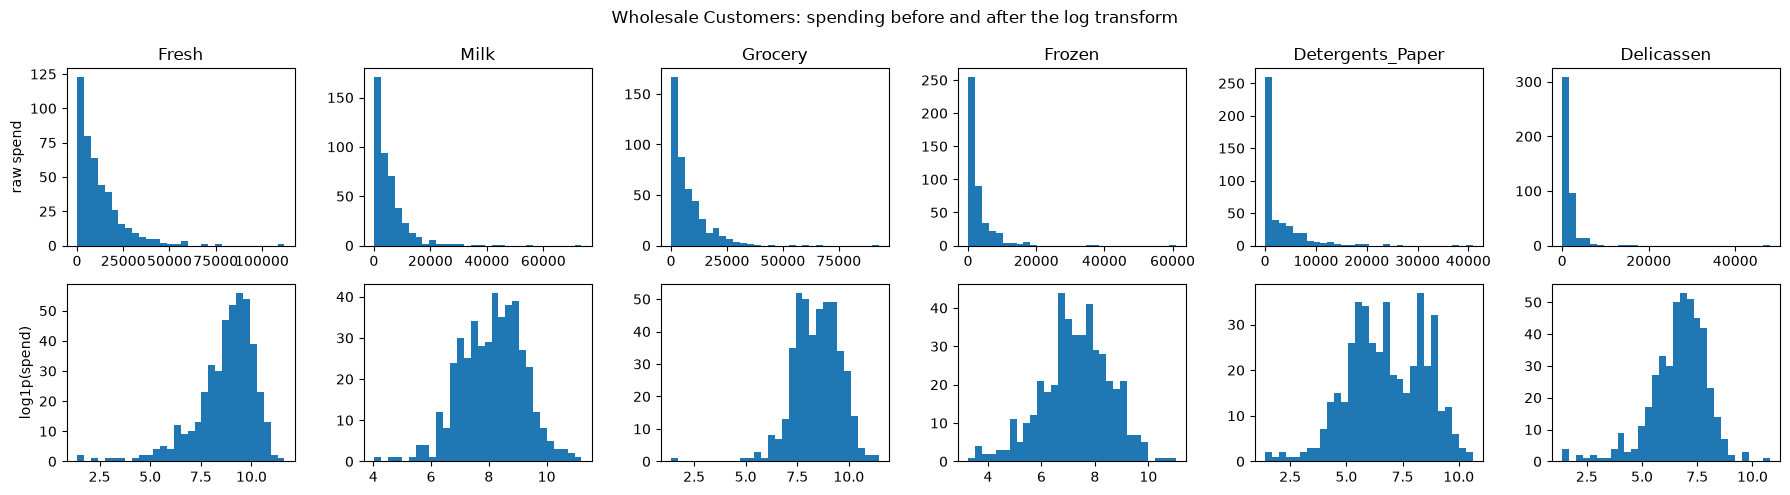

In [5]:
# Source: matplotlib pyplot.hist; one column per feature, raw spend on top, log1p spend below
fig, axes = plt.subplots(2, len(SPEND_COLS), figsize=(18, 5))
for i, col in enumerate(SPEND_COLS):
    axes[0, i].hist(wholesale[col], bins=30)
    axes[0, i].set_title(col)
    axes[1, i].hist(log_spend[col], bins=30)
axes[0, 0].set_ylabel("raw spend")
axes[1, 0].set_ylabel("log1p(spend)")
fig.suptitle("Wholesale Customers: spending before and after the log transform")
plt.tight_layout()
plt.savefig("figures/wholesale_log_hist.png", dpi=150)
plt.show()

#### Synthetic Geometrical & Anomaly Benchmark (Track B)

DEFAULT (confirm with TA): we generate the 1,500 points ourselves: 700 on two concentric circles, 700 on two moons, and 100 injected noise outliers.

In [6]:
# Source: sklearn example "Comparing different clustering algorithms on toy datasets": make_circles(factor=0.5, noise=0.05) and make_moons(noise=0.05)
N_CIRCLES, N_MOONS, N_OUTLIERS = 700, 700, 100

X_circles, y_circles = make_circles(n_samples=N_CIRCLES, factor=0.5, noise=0.05, random_state=RANDOM_STATE)
X_moons, y_moons = make_moons(n_samples=N_MOONS, noise=0.05, random_state=RANDOM_STATE)

# Custom: shift the moons right by 3 so the two shapes don't overlap
X_moons = X_moons + [3.0, 0.0]

In [7]:
# Source: sklearn example "Outlier detection with Local Outlier Factor (LOF)": outliers drawn with np.random.uniform, stacked with np.r_
# Custom: the uniform box is the data's own range plus 0.5, so some outliers land between and inside the shapes (local anomalies)
np.random.seed(RANDOM_STATE)
X_inliers = np.r_[X_circles, X_moons]
X_outliers = np.random.uniform(low=X_inliers.min(axis=0) - 0.5, high=X_inliers.max(axis=0) + 0.5,
                               size=(N_OUTLIERS, 2))

X_synth = np.r_[X_inliers, X_outliers]

# true shape of each point: 0 outer circle, 1 inner circle, 2 and 3 the two moons, -1 injected outlier
y_synth = np.r_[y_circles, y_moons + 2, -np.ones(N_OUTLIERS, dtype=int)]
is_outlier = y_synth == -1

print("X_synth:", X_synth.shape, "| outliers:", is_outlier.sum(), "| points per shape:", np.unique(y_synth, return_counts=True))

X_synth: (1500, 2) | outliers: 100 | points per shape: (array([-1,  0,  1,  2,  3]), array([100, 350, 350, 350, 350]))


### Shared scatter plot

Every cluster scatter plot in the report uses this function, so K-Means, hierarchical, DBSCAN, and LOF plots all share one look. Label -1 (DBSCAN noise, or an outlier) is always a black x.

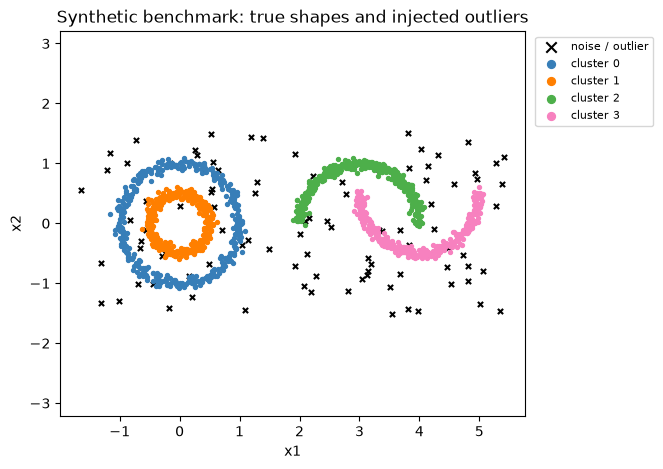

In [8]:
# Custom: one scatter style for the whole report; the colours are the palette from the sklearn example
# "Comparing different clustering algorithms on toy datasets", which also draws noise (-1) in black
CLUSTER_COLORS = ["#377eb8", "#ff7f00", "#4daf4a", "#f781bf", "#a65628",
                  "#984ea3", "#999999", "#e41a1c", "#dede00"]


def plot_clusters(X, labels, title, ax=None, filename=None, xlabel="x1", ylabel="x2"):
    """Scatter the first two columns of X coloured by label; -1 is drawn as black x.
    For Wholesale (6 columns) pass a 2D projection, not X_wholesale itself."""
    labels = np.asarray(labels)
    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 5))
    for k in np.unique(labels):
        pts = X[labels == k]
        if k == -1:
            ax.scatter(pts[:, 0], pts[:, 1], s=14, c="black", marker="x", label="noise / outlier")
        else:
            ax.scatter(pts[:, 0], pts[:, 1], s=8, color=CLUSTER_COLORS[k % len(CLUSTER_COLORS)], label=f"cluster {k}")
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_aspect("equal", adjustable="datalim")
    ax.legend(markerscale=2, fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
    if filename:
        ax.figure.savefig(f"figures/{filename}", dpi=150, bbox_inches="tight")
    return ax


plot_clusters(X_synth, y_synth, "Synthetic benchmark: true shapes and injected outliers", filename="synth_truth.png")
plt.show()

### Handoff files (swapped Thu Nov 19)

Each track saves its synthetic-data result with save_handoff, and the other track reads it with pd.read_csv. A file holds one row per point of X_synth, in order, with columns x1, x2, label. A second one-row file holds the silhouette score and how many noise points were left out of it.

Until the real runs exist, the cell below writes placeholder files that use the true shapes as labels and leave the silhouette blank. This lets Track A build the Challenge A side-by-side plot today. The real files overwrite them.

In [ ]:
# Custom: the handoff format agreed in the contract, Section 3
def save_handoff(method, labels, silhouette, n_noise_excluded=0):
    """method is "kmeans" (Track A) or "dbscan" (Track B)."""
    pd.DataFrame({"x1": X_synth[:, 0], "x2": X_synth[:, 1], "label": labels}).to_csv(
        f"handoff/{method}_synth.csv", index=False)
    pd.DataFrame([{"method": method, "silhouette": silhouette, "n_noise_excluded": n_noise_excluded}]).to_csv(
        f"handoff/{method}_summary.csv", index=False)


# placeholders, written only if the real file does not exist yet
for method in ["kmeans", "dbscan"]:
    if not os.path.exists(f"handoff/{method}_synth.csv"):
        save_handoff(method, y_synth, np.nan)

print(pd.read_csv("handoff/dbscan_synth.csv").head(3))
print(pd.read_csv("handoff/dbscan_summary.csv"))

## Task 4.2: K-Means++ Optimization & Silhouette Analysis (Track A)

Spec: "Execute K-Means++ across K ∈ [2, 10]. Plot the Elbow Curve (Inertia/SSE vs. K) and compute Silhouette Coefficients s(i) = (b(i) − a(i)) / max(a(i), b(i)) to select optimal K."

Runs on both datasets. On X_synth it shows K-Means splitting the rings and moons, and at the chosen K Track A calls save_handoff("kmeans", ...).

In [27]:
#imports for KMeans
from sklearn.cluster import KMeans

from sklearn.metrics import silhouette_score


In [28]:
# Track A: Task 4.2

#first we need to implement the Kmean ++ models for each k 2-10

kRange = range(2, 11)

def k_means_model_gen(X, kRange):
    
    results = []
    models = {}
    
    for k in kRange:
        model = KMeans(n_clusters=k, init="k-means++", n_init=20, random_state=RANDOM_STATE)
        
        labels = model.fit_predict(X)
        
        results.append({"K": k, "Inertia": model.inertia_, "Silhouette": silhouette_score(X, labels), "Iterations": model.n_iter_})
        
        models[k] = model
    
    resultsDF = pd.DataFrame(results)
    
    bestK = int(resultsDF.loc[
        resultsDF["Silhouette"].idxmax(), "K"
    ])
    
    return resultsDF, models, bestK

In [33]:
datasets = {"Wholesale": X_wholesale, "Synthetic": X_synth}

kmeans_results = {}

for name, X in datasets.items():

    results, models, best_k = k_means_model_gen(X, kRange)

    kmeans_results[name] = {
        "results": results,
        "models": models,
        "best_k": best_k
    }

    print(f"\nDataset: {name}")
    print(results.round(4))
    print(f"Optimal K by Silhouette: {best_k}")

c:\Users\Rodri\.conda\envs\cse4334\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
c:\Users\Rodri\.conda\envs\cse4334\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
c:\Users\Rodri\.conda\envs\cse4334\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
c:\Users\Rodri\.conda\envs\cse4334\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans 


Dataset: Wholesale
    K    Inertia  Silhouette  Iterations
0   2  1844.0641      0.2903          14
1   3  1553.3861      0.2579           8
2   4  1386.8234      0.1892          14
3   5  1266.1494      0.1916          43
4   6  1174.1479      0.1923          12
5   7  1088.0934      0.1929          13
6   8  1024.8871      0.1906          26
7   9   975.3302      0.2005          32
8  10   928.0214      0.1963          17
Optimal K by Silhouette: 2


c:\Users\Rodri\.conda\envs\cse4334\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(
c:\Users\Rodri\.conda\envs\cse4334\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(
c:\Users\Rodri\.conda\envs\cse4334\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(
c:\Users\Rodri\.conda\envs\cse4334\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans 


Dataset: Synthetic
    K    Inertia  Silhouette  Iterations
0   2  1313.9395      0.6599           4
1   3   855.2365      0.5469           5
2   4   673.3485      0.4066           6
3   5   552.6203      0.4175           6
4   6   446.1889      0.3944           5
5   7   363.5933      0.4139           8
6   8   308.2193      0.4071          14
7   9   272.1423      0.4118          11
8  10   239.7655      0.4225          11
Optimal K by Silhouette: 2


c:\Users\Rodri\.conda\envs\cse4334\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(


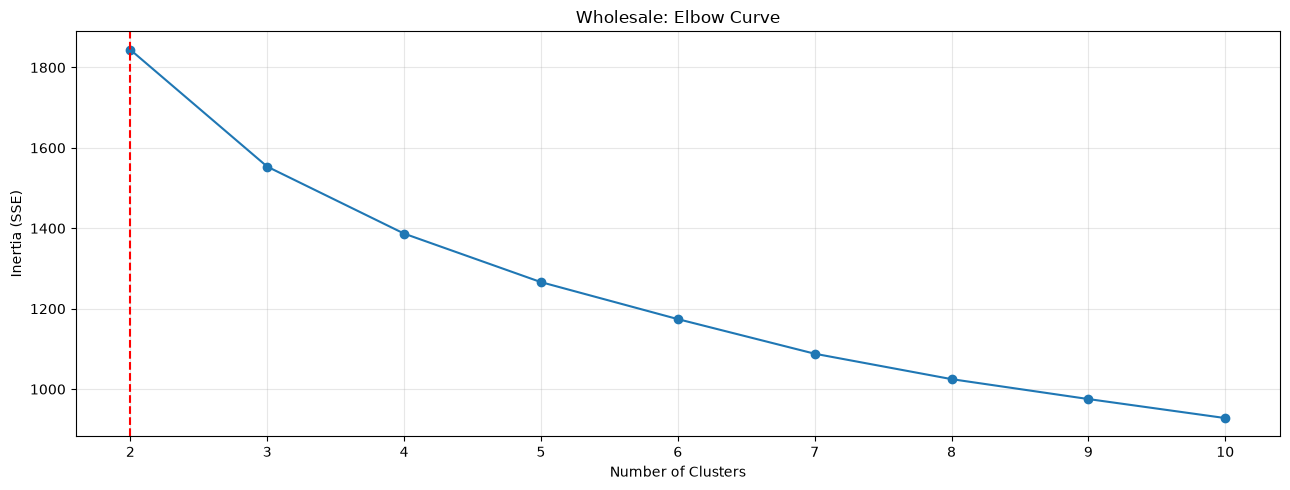

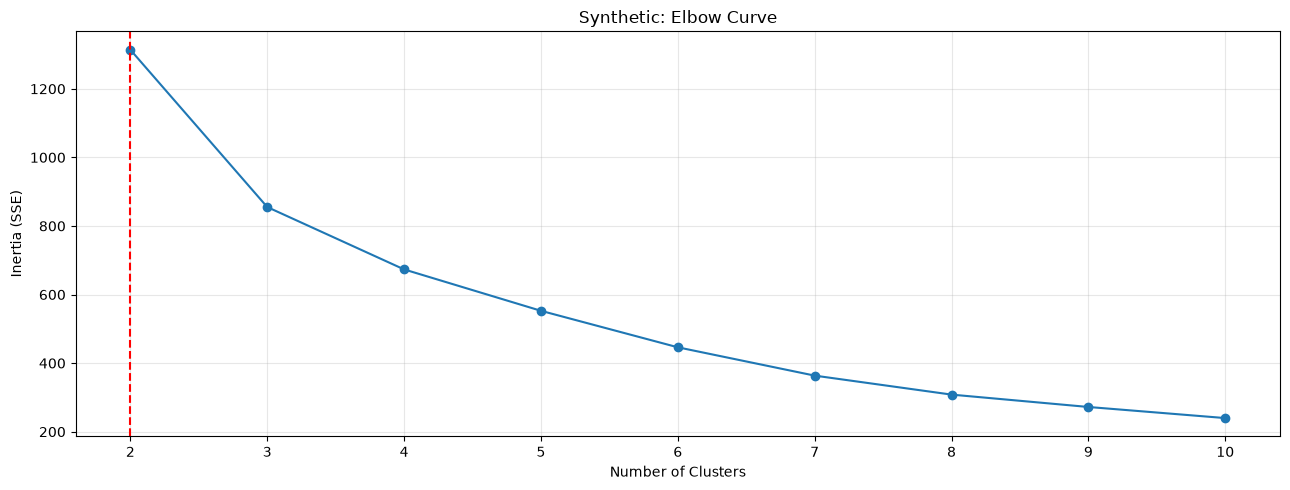

In [30]:
def plot_kmeans_metrics(results, best_k, name):

    fig, ax = plt.subplots(figsize=(13, 5))

    ax.plot(
        results["K"],
        results["Inertia"],
        marker="o"
    )

    ax.set_title(f"{name}: Elbow Curve")
    ax.set_xlabel("Number of Clusters")
    ax.set_ylabel("Inertia (SSE)")
    ax.set_xticks(results["K"])
    ax.grid(alpha=0.3)


    ax.axvline(
        best_k,
        color="red",
        linestyle="--",
        label=f"Best K = {best_k}"
    )


    plt.tight_layout()
    plt.show()
    


plot_kmeans_metrics(kmeans_results["Wholesale"].get("results"), kmeans_results["Wholesale"].get("best_k"), "Wholesale")
plot_kmeans_metrics(kmeans_results["Synthetic"].get("results"), kmeans_results["Synthetic"].get("best_k"), "Synthetic")

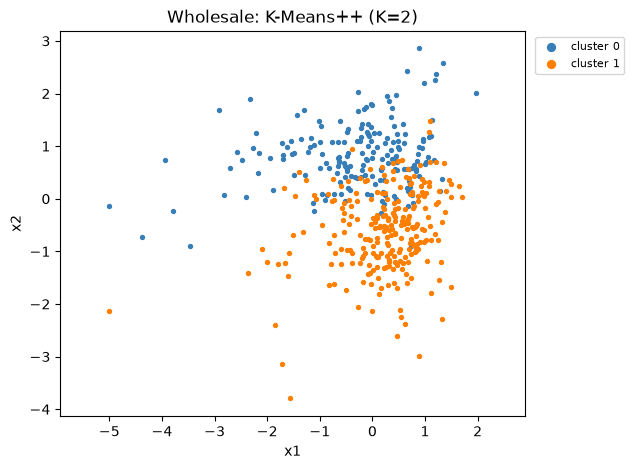

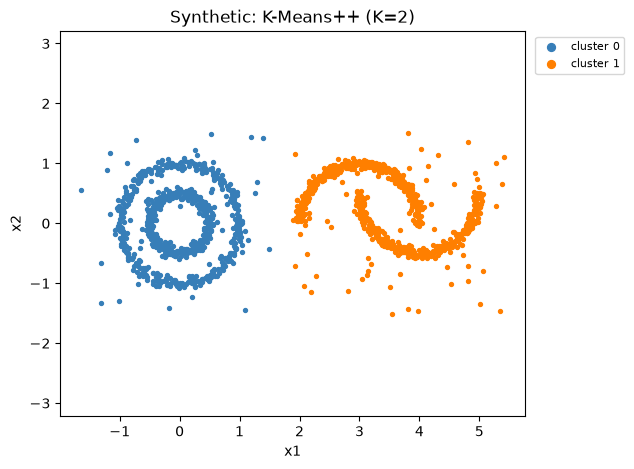

In [31]:
for name, X in datasets.items():

    result = kmeans_results[name]

    best_k = result["best_k"]

    model = result["models"][best_k]

    plot_clusters(
        X,
        model.labels_,
        f"{name}: K-Means++ (K={best_k})"
    )

## Task 4.3: Hierarchical Linkage Benchmarking (Track A)

Spec: "Apply Agglomerative Hierarchical Clustering using 4 linkage criteria: Single (MIN), Complete (MAX), Average, and Ward's Method. Render dendrogram trees using scipy.cluster.hierarchy."

In [34]:
from sklearn.cluster import AgglomerativeClustering

In [35]:
# Track A: Task 4.3

linkageMethods = ["single", "complete", "average", "ward"]

def hierarchichal_model_gen(X, kRange, linkageMethods):
    
    results = []
    models = {}
    
    for method in linkageMethods:
        for k in kRange:
            model = AgglomerativeClustering(n_clusters=k, metric="euclidean", linkage=method)
            
            labels = model.fit_predict(X)
            
            results.append({"Linkage":method, "K":k, "Silhouette": silhouette_score(X, labels)})
            
            models[(method, k)] = model
    
    return pd.DataFrame(results), models
    

In [36]:
hierarchichalResults = {}

for name, X in datasets.items():
    results, models = hierarchichal_model_gen(X, kRange, linkageMethods)
    
    hierarchichalResults[name] = {"results": results, "models":models}
    
    print(f"\nDataset: {name}")

    best_indices = results.groupby(
        "Linkage"
    )["Silhouette"].idxmax()

    best_results = results.loc[best_indices]

    print(best_results.round(4))
    


Dataset: Wholesale
     Linkage  K  Silhouette
18   average  2      0.5691
9   complete  2      0.3220
0     single  2      0.5700
27      ward  2      0.2585

Dataset: Synthetic
     Linkage  K  Silhouette
18   average  2      0.6583
9   complete  2      0.4937
4     single  6      0.1625
27      ward  2      0.6590


In [37]:
#using cluster.hierarchy to make the dandogram trees
from scipy.cluster.hierarchy import linkage, dendrogram


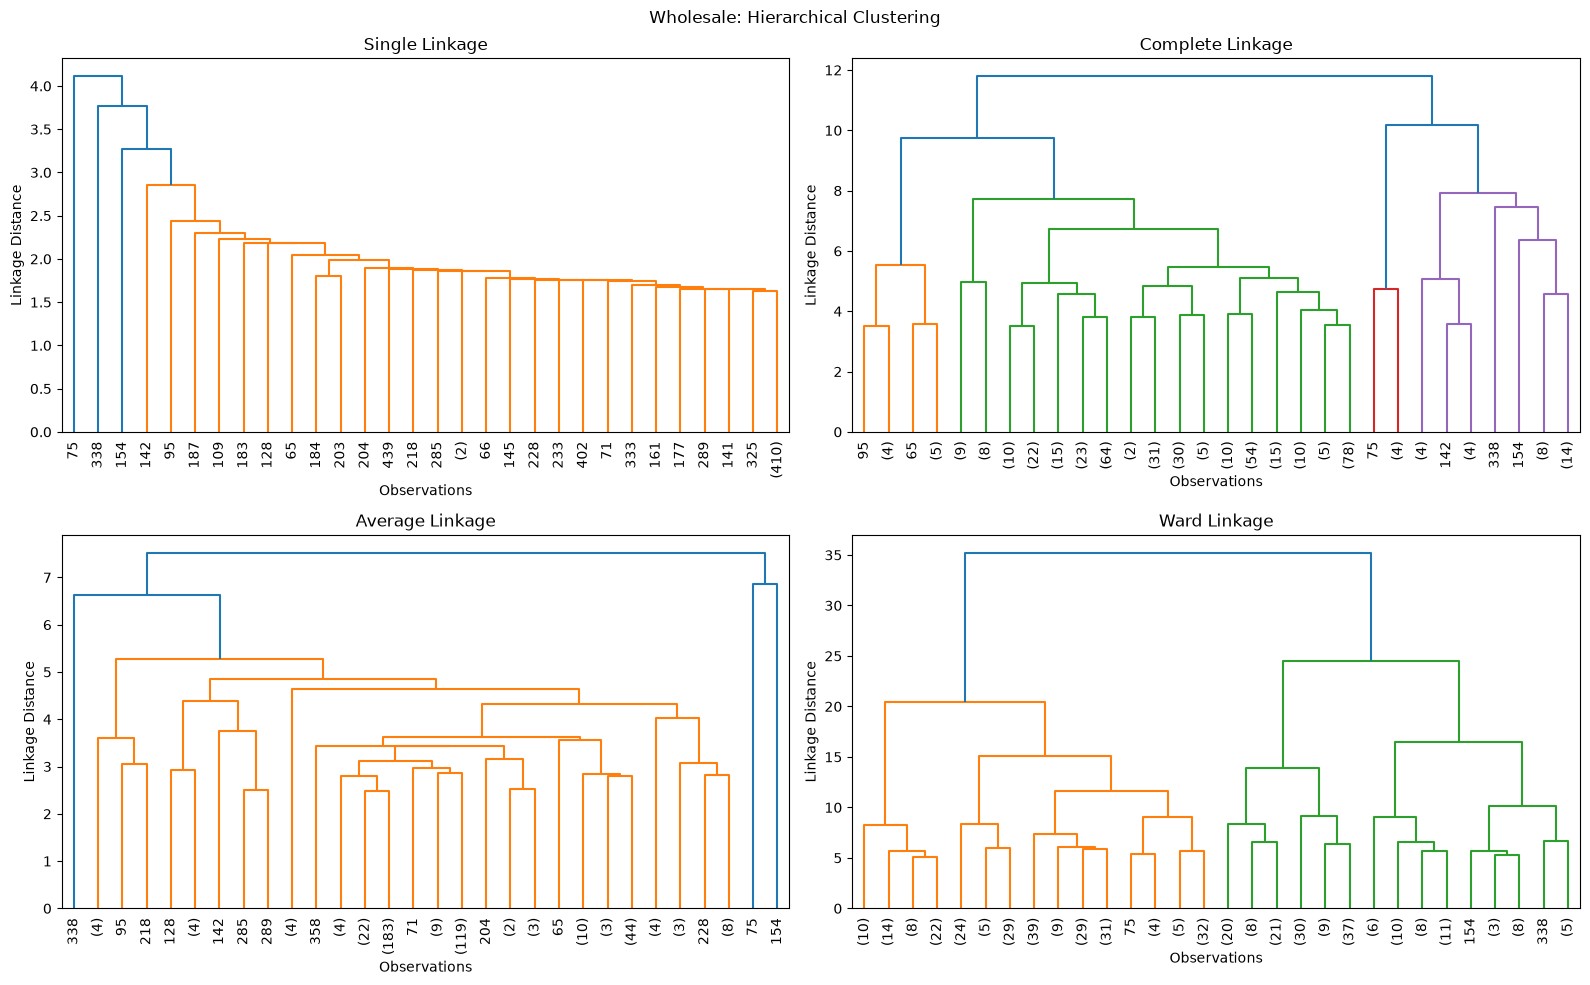

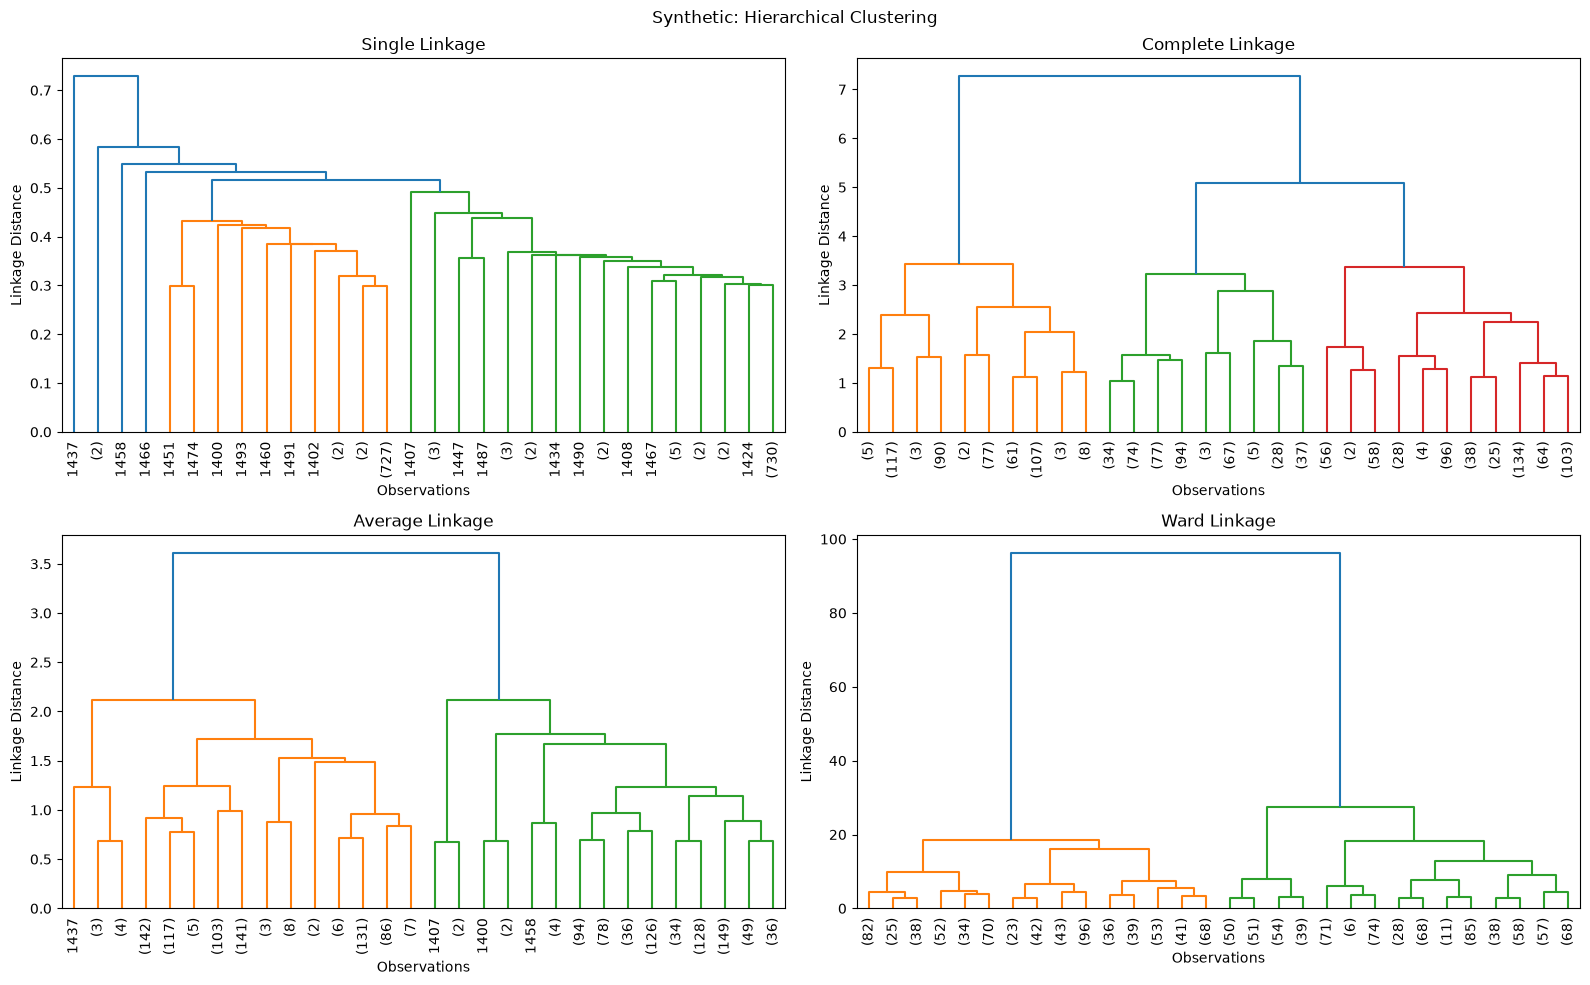

In [38]:
def plot_dendogram_trees(X, datasetName, linkageMethods):
    fig, axes = plt.subplots(2, 2, figsize=(16, 10))
    
    for ax, method in zip(axes.flatten(), linkageMethods):

        Z = linkage(
            X,
            method=method,
            metric="euclidean"
        )

        dendrogram(
            Z,
            ax=ax,
            truncate_mode="lastp",
            p=30,
            leaf_rotation=90
        )

        ax.set_title(f"{method.capitalize()} Linkage")
        ax.set_xlabel("Observations")
        ax.set_ylabel("Linkage Distance")

    fig.suptitle(f"{datasetName}: Hierarchical Clustering")

    plt.tight_layout()
    plt.show()
    
plot_dendogram_trees(X_wholesale, "Wholesale", linkageMethods)
plot_dendogram_trees(X_synth, "Synthetic", linkageMethods)


## Task 4.4: DBSCAN Density Partitioning (Track B)

Spec: "Construct a K-distance plot (k = MinPts) to identify the 'knee' for optimal Eps parameter selection. Partition data into Core, Border, and Noise points."

Starting points from the contract: MinPts = 4 on X_synth and 12 on X_wholesale. Track B calls save_handoff("dbscan", ...) with the silhouette computed without the noise points.

In [ ]:
# Track B: Task 4.4

## Task 4.5: Anomaly Detection, LOF vs. Global Bounds (Track B)

Spec: "Implement Local Outlier Factor (LOF) and distance-based scoring. Compare LOF local density anomaly scores against global statistical Z-score/Grubbs bounds."

is_outlier is the ground truth for scoring each method. SciPy has no Grubbs test, so it is written from the formula with scipy.stats.t and marked Custom.

In [ ]:
# Track B: Task 4.5

## Report figures for Part I

The written answers to Challenges A, B, and C go in the PDF report. These cells make the figures and worked numbers the answers use.

### Challenge A: side-by-side K-Means vs DBSCAN on the synthetic data (Track A)

Reads handoff/kmeans_synth.csv and handoff/dbscan_synth.csv, and both summary files, for the Silhouette Paradox.

In [ ]:
# Track A: Challenge A figure


### Challenge B: chaining-effect example (Track A)

In [ ]:
# Track A: Challenge B example

### Challenge C: coordinate scenario with LOF ≫ 1 (Track B)

In [ ]:
# Track B: Challenge C example

## Part II: AI Integration (Track B)

The required prompt: an AI writes a Python script for DBSCAN parameter selection and LOF anomaly detection. Its code is pasted here unedited, then audited: did it build a k-distance plot to pick Eps, or guess arbitrary parameters? Every prompt we used is logged in the AI Prompt Appendix.

In [ ]:
# Track B: AI-generated code, unedited